In [2]:
import sys
from pathlib import Path

print("Python:", sys.executable)
print("Notebook folder:", Path.cwd())
print("Datasets found:", (Path.cwd().parent / "all_datasets").is_dir())
print("Passenger script found:", (Path.cwd() / "predict_passenger.py").is_file())


Python: C:\Users\Hp\anaconda3\envs\ml\python.exe
Notebook folder: C:\Users\Hp\Documents\UTP-MACHINE-LEARNING\all_experiments
Datasets found: True
Passenger script found: True


In [3]:
import sys
from pathlib import Path

print("Python:", sys.executable)
print("Notebook folder:", Path.cwd())
print("Datasets found:", (Path.cwd().parent / "all_datasets").is_dir())
print("Passenger script found:", (Path.cwd() / "predict_passenger.py").is_file())

Python: C:\Users\Hp\anaconda3\envs\ml\python.exe
Notebook folder: C:\Users\Hp\Documents\UTP-MACHINE-LEARNING\all_experiments
Datasets found: True
Passenger script found: True


In [4]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV, StratifiedKFold, train_test_split
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

PROJECT_ROOT = Path.cwd().parent
DATA = PROJECT_ROOT / "all_datasets"
MODELS = PROJECT_ROOT / "models"
MODELS.mkdir(exist_ok=True)

def make_preprocess(num_cols, cat_cols):
    return ColumnTransformer([
        ("num", Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ]), num_cols),
        ("cat", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), cat_cols),
    ])

print("Lab 2 setup ready!")
print("scikit-learn:", sklearn.__version__)

Lab 2 setup ready!
scikit-learn: 1.9.1


In [5]:
insurance = pd.read_csv(DATA / "medical_cost_personal_dataset.csv")
display(insurance.head())

X = insurance.drop(columns="charges")
y = insurance["charges"]

num_cols = ["age", "bmi", "children"]
cat_cols = ["sex", "smoker", "region"]

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training rows:", len(X_train))
print("Validation rows:", len(X_valid))

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


Training rows: 1070
Validation rows: 268


In [6]:
fitted = {}
predictions = {}

for name, estimator in {
    "linear regression": LinearRegression(),
    "ridge": Ridge(alpha=10.0),
}.items():
    model = Pipeline([
        ("preprocess", make_preprocess(num_cols, cat_cols)),
        ("model", estimator),
    ])

    model.fit(X_train, y_train)
    fitted[name] = model
    predictions[name] = model.predict(X_valid)
    pred = predictions[name]

    print(f"\n{name}")
    print("MAE:", round(mean_absolute_error(y_valid, pred), 2))
    print("RMSE:", round(np.sqrt(mean_squared_error(y_valid, pred)), 2))
    print("R2:", round(r2_score(y_valid, pred), 3))


linear regression
MAE: 4181.19
RMSE: 5796.28
R2: 0.784

ridge
MAE: 4238.82
RMSE: 5821.59
R2: 0.782


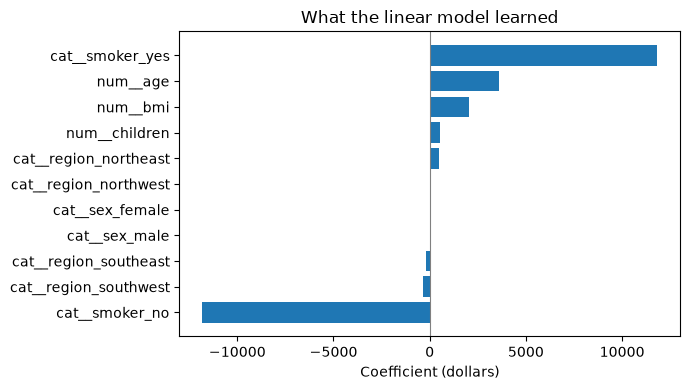

In [7]:
linear = fitted["linear regression"]
names = linear.named_steps["preprocess"].get_feature_names_out()
coefs = pd.Series(
    linear.named_steps["model"].coef_,
    index=names
).sort_values()

plt.figure(figsize=(7, 4))
plt.barh(coefs.index, coefs.values)
plt.axvline(0, color="grey", linewidth=0.8)
plt.xlabel("Coefficient (dollars)")
plt.title("What the linear model learned")
plt.tight_layout()
plt.show()

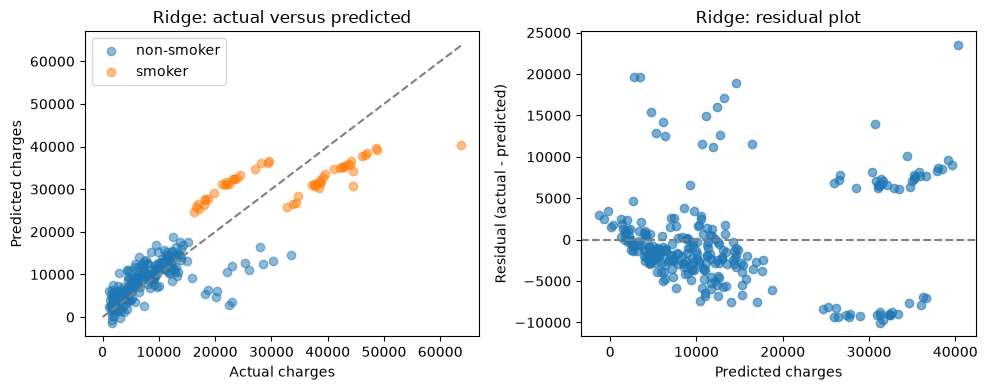

In [8]:
ridge_pred = predictions["ridge"]
residual = y_valid.to_numpy() - ridge_pred
is_smoker = (X_valid["smoker"] == "yes").to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].scatter(
    y_valid[~is_smoker], ridge_pred[~is_smoker],
    alpha=0.5, label="non-smoker"
)
axes[0].scatter(
    y_valid[is_smoker], ridge_pred[is_smoker],
    alpha=0.5, label="smoker"
)
axes[0].plot(
    [0, y_valid.max()], [0, y_valid.max()],
    linestyle="--", color="grey"
)
axes[0].set_xlabel("Actual charges")
axes[0].set_ylabel("Predicted charges")
axes[0].set_title("Ridge: actual versus predicted")
axes[0].legend()

axes[1].scatter(ridge_pred, residual, alpha=0.6)
axes[1].axhline(0, linestyle="--", color="grey")
axes[1].set_xlabel("Predicted charges")
axes[1].set_ylabel("Residual (actual - predicted)")
axes[1].set_title("Ridge: residual plot")

plt.tight_layout()
plt.show()

Train: 2011-01-01 to 2012-08-06
Valid: 2012-08-07 to 2012-12-31
Daily MAE: 1040.4
Mean daily validation demand: 5897.8


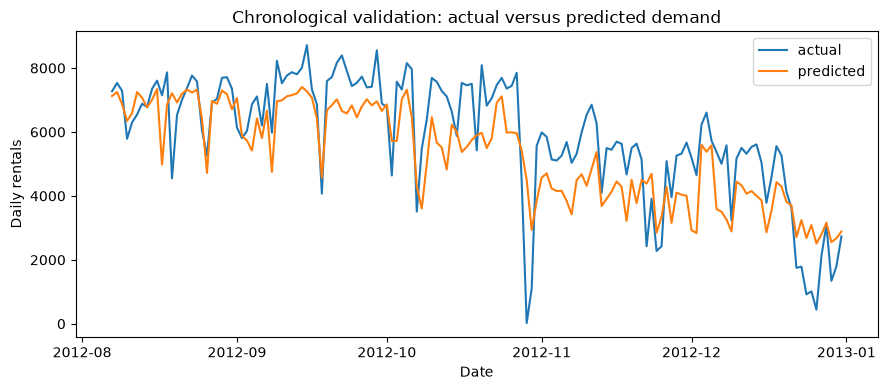

In [9]:
bikes = pd.read_csv(DATA / "bike_sharing_dataset_day.csv")
bikes["dteday"] = pd.to_datetime(bikes["dteday"])
bikes = bikes.sort_values("dteday").reset_index(drop=True)

# Exclude casual and registered because their sum equals the target cnt.
bike_cat = [
    "season", "yr", "mnth", "holiday",
    "weekday", "workingday", "weathersit"
]
bike_num = ["temp", "atemp", "hum", "windspeed"]

X_b = bikes[bike_cat + bike_num]
y_b = bikes["cnt"]

cut = int(len(bikes) * 0.80)

Xb_train, Xb_valid = X_b.iloc[:cut], X_b.iloc[cut:]
yb_train, yb_valid = y_b.iloc[:cut], y_b.iloc[cut:]
dates_valid = bikes["dteday"].iloc[cut:]

print("Train:", bikes["dteday"].iloc[0].date(),
      "to", bikes["dteday"].iloc[cut - 1].date())
print("Valid:", dates_valid.iloc[0].date(),
      "to", dates_valid.iloc[-1].date())

bike_model = Pipeline([
    ("preprocess", ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), bike_cat),
        ("num", "passthrough", bike_num),
    ])),
    ("model", RandomForestRegressor(
        n_estimators=400,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )),
])

bike_model.fit(Xb_train, yb_train)
bike_pred = bike_model.predict(Xb_valid)

print("Daily MAE:", round(mean_absolute_error(yb_valid, bike_pred), 1))
print("Mean daily validation demand:", round(yb_valid.mean(), 1))

plt.figure(figsize=(9, 4))
plt.plot(dates_valid, yb_valid.to_numpy(), label="actual")
plt.plot(dates_valid, bike_pred, label="predicted")
plt.xlabel("Date")
plt.ylabel("Daily rentals")
plt.title("Chronological validation: actual versus predicted demand")
plt.legend()
plt.tight_layout()
plt.show()

Training rows: 13903
Validation rows: 3476
Hourly MAE: 56.5
Mean hourly validation demand: 248.8


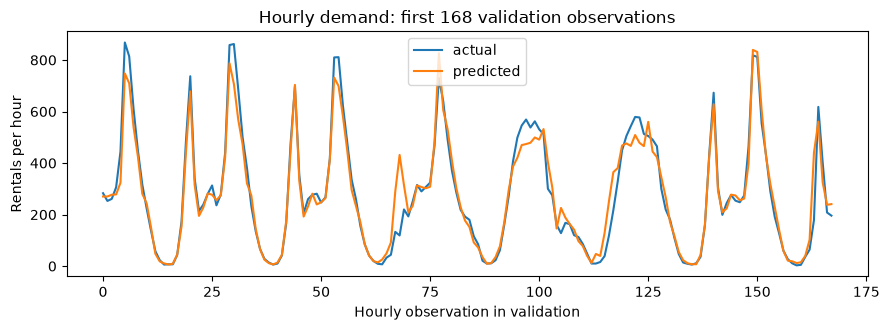

In [10]:
hourly = pd.read_csv(DATA / "bike_sharing_dataset_hour.csv")
hourly["dteday"] = pd.to_datetime(hourly["dteday"])
hourly = hourly.sort_values(["dteday", "hr"]).reset_index(drop=True)

hour_cat = bike_cat + ["hr"]
Xh = hourly[hour_cat + bike_num]
yh = hourly["cnt"]

cut_h = int(len(hourly) * 0.80)

hour_model = Pipeline([
    ("preprocess", ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), hour_cat),
        ("num", "passthrough", bike_num),
    ])),
    ("model", RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )),
])

hour_model.fit(Xh.iloc[:cut_h], yh.iloc[:cut_h])
hour_pred = hour_model.predict(Xh.iloc[cut_h:])

print("Training rows:", cut_h)
print("Validation rows:", len(hourly) - cut_h)
print("Hourly MAE:",
      round(mean_absolute_error(yh.iloc[cut_h:], hour_pred), 1))
print("Mean hourly validation demand:",
      round(yh.iloc[cut_h:].mean(), 1))

# Display the first 168 validation observations.
n_plot = min(24 * 7, len(hour_pred))

plt.figure(figsize=(9, 3.4))
plt.plot(
    range(n_plot),
    yh.iloc[cut_h:].to_numpy()[:n_plot],
    label="actual"
)
plt.plot(range(n_plot), hour_pred[:n_plot], label="predicted")
plt.xlabel("Hourly observation in validation")
plt.ylabel("Rentals per hour")
plt.title("Hourly demand: first 168 validation observations")
plt.legend()
plt.tight_layout()
plt.show()

Majority-class baseline accuracy: 0.614
logistic       accuracy=0.776 roc_auc=0.842
random_forest  accuracy=0.798 roc_auc=0.834
Threshold 0.30: precision=0.64 recall=0.81
Threshold 0.50: precision=0.72 recall=0.67
Threshold 0.70: precision=0.90 recall=0.50


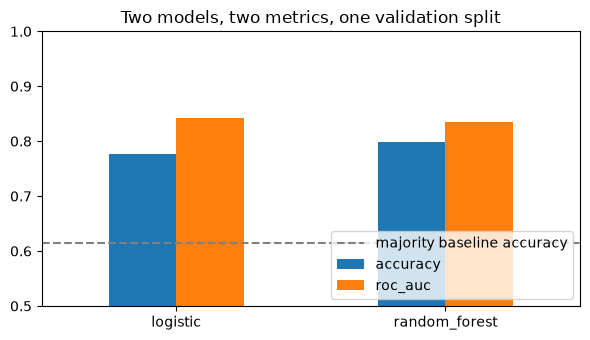

In [11]:
titanic = pd.read_csv(DATA / "titanic_dataset.csv")

features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]
t_num = ["Age", "SibSp", "Parch", "Fare"]
t_cat = ["Pclass", "Sex", "Embarked"]

X_t = titanic[features]
y_t = titanic["Survived"]

Xt_train, Xt_valid, yt_train, yt_valid = train_test_split(
    X_t, y_t,
    test_size=0.25,
    random_state=42,
    stratify=y_t
)

print("Majority-class baseline accuracy:",
      round(1 - yt_valid.mean(), 3))

scores = {}
fitted_t = {}

for name, estimator in {
    "logistic": LogisticRegression(max_iter=1000),
    "random_forest": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42
    ),
}.items():
    pipe = Pipeline([
        ("preprocess", make_preprocess(t_num, t_cat)),
        ("model", estimator),
    ])

    pipe.fit(Xt_train, yt_train)
    fitted_t[name] = pipe

    scores[name] = {
        "accuracy": accuracy_score(yt_valid, pipe.predict(Xt_valid)),
        "roc_auc": roc_auc_score(
            yt_valid, pipe.predict_proba(Xt_valid)[:, 1]
        ),
    }

    print(
        f"{name:14s} "
        f"accuracy={scores[name]['accuracy']:.3f} "
        f"roc_auc={scores[name]['roc_auc']:.3f}"
    )

# Keep the same model; change only the decision threshold.
prob_t = fitted_t["logistic"].predict_proba(Xt_valid)[:, 1]

for threshold in [0.30, 0.50, 0.70]:
    pred_t = (prob_t >= threshold).astype(int)
    print(
        f"Threshold {threshold:.2f}: "
        f"precision={precision_score(yt_valid, pred_t):.2f} "
        f"recall={recall_score(yt_valid, pred_t):.2f}"
    )

pd.DataFrame(scores).T.plot.bar(
    figsize=(6, 3.5), ylim=(0.5, 1.0), rot=0
)
plt.axhline(
    1 - yt_valid.mean(),
    linestyle="--",
    color="grey",
    label="majority baseline accuracy"
)
plt.title("Two models, two metrics, one validation split")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

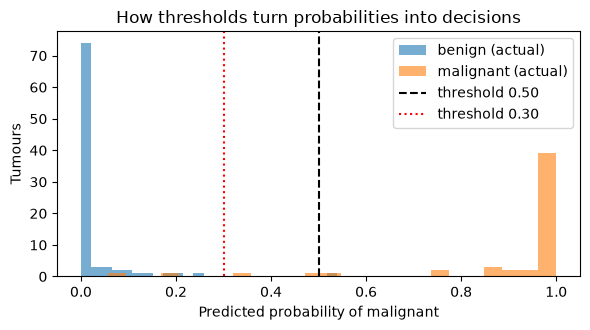

In [12]:
cancer = pd.read_csv(DATA / "breast_cancer_dataset.csv")

X_c = cancer.drop(
    columns=["id", "diagnosis", "Unnamed: 32"],
    errors="ignore"
)
y_c = (cancer["diagnosis"] == "M").astype(int)

Xc_train, Xc_valid, yc_train, yc_valid = train_test_split(
    X_c, y_c,
    test_size=0.25,
    random_state=42,
    stratify=y_c
)

cancer_model = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000)),
])

cancer_model.fit(Xc_train, yc_train)
prob = cancer_model.predict_proba(Xc_valid)[:, 1]

plt.figure(figsize=(6, 3.4))
plt.hist(prob[yc_valid == 0], bins=25, alpha=0.6,
         label="benign (actual)")
plt.hist(prob[yc_valid == 1], bins=25, alpha=0.6,
         label="malignant (actual)")
plt.axvline(0.50, color="black", linestyle="--",
            label="threshold 0.50")
plt.axvline(0.30, color="red", linestyle=":",
            label="threshold 0.30")
plt.xlabel("Predicted probability of malignant")
plt.ylabel("Tumours")
plt.title("How thresholds turn probabilities into decisions")
plt.legend()
plt.tight_layout()
plt.show()


Threshold = 0.50
[[89  1]
 [ 4 49]]
              precision    recall  f1-score   support

      benign      0.957     0.989     0.973        90
   malignant      0.980     0.925     0.951        53

    accuracy                          0.965       143
   macro avg      0.968     0.957     0.962       143
weighted avg      0.966     0.965     0.965       143



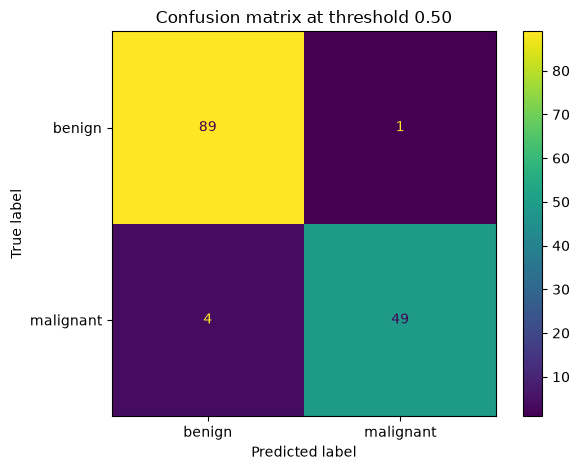


Threshold = 0.30
[[89  1]
 [ 2 51]]
              precision    recall  f1-score   support

      benign      0.978     0.989     0.983        90
   malignant      0.981     0.962     0.971        53

    accuracy                          0.979       143
   macro avg      0.979     0.976     0.977       143
weighted avg      0.979     0.979     0.979       143



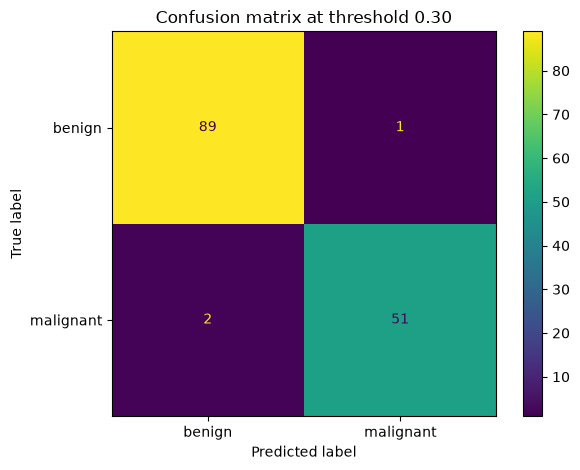

In [13]:
for threshold in [0.50, 0.30]:
    pred = (prob >= threshold).astype(int)

    print(f"\nThreshold = {threshold:.2f}")
    print(confusion_matrix(yc_valid, pred))
    print(classification_report(
        yc_valid, pred,
        target_names=["benign", "malignant"],
        digits=3
    ))

    ConfusionMatrixDisplay.from_predictions(
        yc_valid, pred,
        display_labels=["benign", "malignant"]
    )
    plt.title(f"Confusion matrix at threshold {threshold:.2f}")
    plt.tight_layout()
    plt.show()

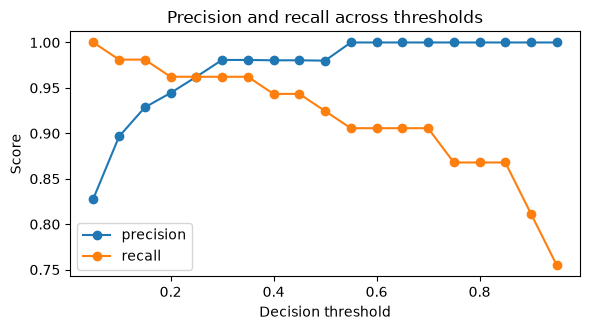

ROC AUC: 0.996
Average precision: 0.994


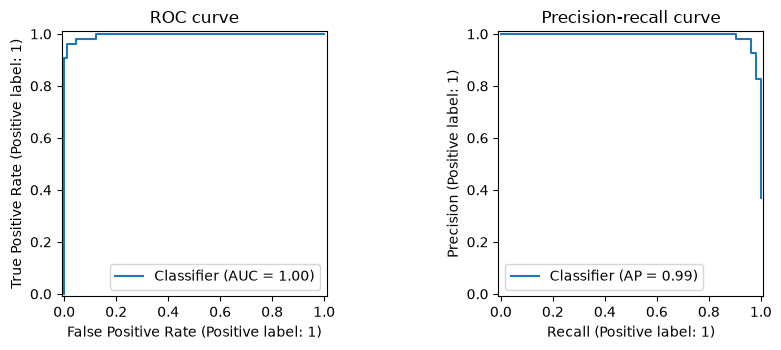

In [14]:
# Show how precision and recall change with the threshold.
thresholds = np.linspace(0.05, 0.95, 19)

precisions = [
    precision_score(yc_valid, (prob >= t).astype(int), zero_division=0)
    for t in thresholds
]
recalls = [
    recall_score(yc_valid, (prob >= t).astype(int))
    for t in thresholds
]

plt.figure(figsize=(6, 3.4))
plt.plot(thresholds, precisions, marker="o", label="precision")
plt.plot(thresholds, recalls, marker="o", label="recall")
plt.xlabel("Decision threshold")
plt.ylabel("Score")
plt.title("Precision and recall across thresholds")
plt.legend()
plt.tight_layout()
plt.show()

# Evaluate probability ranking, rather than one threshold.
print("ROC AUC:", round(roc_auc_score(yc_valid, prob), 3))
print("Average precision:", round(average_precision_score(yc_valid, prob), 3))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))

RocCurveDisplay.from_predictions(yc_valid, prob, ax=axes[0])
axes[0].set_title("ROC curve")

PrecisionRecallDisplay.from_predictions(yc_valid, prob, ax=axes[1])
axes[1].set_title("Precision-recall curve")

plt.tight_layout()
plt.show()

In [15]:
# Part D: tune Titanic logistic regression
X_train, X_test, y_train, y_test = train_test_split(
    X_t, y_t,
    test_size=0.25,
    random_state=42,
    stratify=y_t
)

search = GridSearchCV(
    Pipeline([
        ("preprocess", make_preprocess(t_num, t_cat)),
        ("model", LogisticRegression(max_iter=2000))
    ]),
    param_grid={
        "model__C": [0.01, 0.1, 1.0, 10.0, 100.0],
        "model__class_weight": [None, "balanced"]
    },
    scoring="roc_auc",
    cv=StratifiedKFold(
        n_splits=5, shuffle=True, random_state=42
    ),
    n_jobs=-1
)

search.fit(X_train, y_train)

test_prob = search.predict_proba(X_test)[:, 1]
test_auc = roc_auc_score(y_test, test_prob)

print("Best parameters:", search.best_params_)
print("Best cross-validation ROC AUC:", round(search.best_score_, 3))
print("Holdout ROC AUC:", round(test_auc, 3))

Best parameters: {'model__C': 0.1, 'model__class_weight': 'balanced'}
Best cross-validation ROC AUC: 0.85
Holdout ROC AUC: 0.837


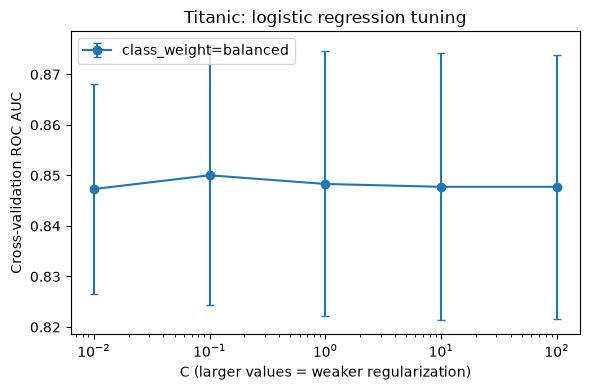

In [16]:
cv_table = pd.DataFrame(search.cv_results_)

plt.figure(figsize=(6, 4))

for weight, group in cv_table.groupby(
    cv_table["param_model__class_weight"].astype(str)
):
    group = group.sort_values("param_model__C")

    plt.errorbar(
        group["param_model__C"].astype(float),
        group["mean_test_score"],
        yerr=group["std_test_score"],
        marker="o",
        capsize=3,
        label=f"class_weight={weight}"
    )

plt.xscale("log")
plt.xlabel("C (larger values = weaker regularization)")
plt.ylabel("Cross-validation ROC AUC")
plt.title("Titanic: logistic regression tuning")
plt.legend()
plt.tight_layout()
plt.show()

The best hyperparameters were C = 0.1 and class_weight = "balanced".
The mean five-fold cross-validation ROC AUC was 0.850, while the
holdout ROC AUC was 0.837. Preprocessing was fitted within each
cross-validation fold through the pipeline.

The holdout is the same split examined in Part C, so this result
is not an independent, previously unseen final test.

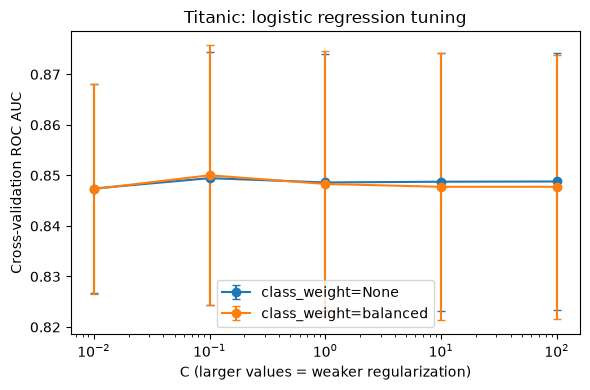

In [17]:
cv_table = pd.DataFrame(search.cv_results_)

# Explicit labels keep both groups in the plot
cv_table["weight_label"] = [
    "None" if p["model__class_weight"] is None else "balanced"
    for p in cv_table["params"]
]
cv_table["C_value"] = [
    float(p["model__C"]) for p in cv_table["params"]
]

plt.figure(figsize=(6, 4))

for weight, group in cv_table.groupby("weight_label"):
    group = group.sort_values("C_value")

    plt.errorbar(
        group["C_value"],
        group["mean_test_score"],
        yerr=group["std_test_score"],
        marker="o",
        capsize=3,
        label=f"class_weight={weight}"
    )

plt.xscale("log")
plt.xlabel("C (larger values = weaker regularization)")
plt.ylabel("Cross-validation ROC AUC")
plt.title("Titanic: logistic regression tuning")
plt.legend()
plt.tight_layout()
plt.show()

In [18]:
# Part E: save the trained pipeline and model card
final_model = search.best_estimator_

MODELS.mkdir(exist_ok=True)
model_path = MODELS / "titanic_survival.joblib"
joblib.dump(final_model, model_path)

card = {
    "task": "predict Titanic survival (1 = survived)",
    "features": features,
    "model": "logistic regression pipeline",
    "best_parameters": search.best_params_,
    "training_rows": int(len(X_train)),
    "final_test_roc_auc": round(float(test_auc), 3),
    "evaluation_note": (
        "The holdout was also examined in Part C; "
        "it is not a previously unseen final test."
    ),
    "decision_threshold": 0.5,
    "scikit_learn_version": sklearn.__version__
}

card_path = MODELS / "titanic_survival_card.json"
card_path.write_text(
    json.dumps(card, indent=2),
    encoding="utf-8"
)

print("Saved model:", model_path)
print("Saved model card:", card_path)

Saved model: C:\Users\Hp\Documents\UTP-MACHINE-LEARNING\models\titanic_survival.joblib
Saved model card: C:\Users\Hp\Documents\UTP-MACHINE-LEARNING\models\titanic_survival_card.json


In [19]:
loaded = joblib.load(MODELS / "titanic_survival.joblib")

new_passengers = pd.DataFrame([
    {
        "Pclass": 1, "Sex": "female", "Age": 29,
        "SibSp": 0, "Parch": 0, "Fare": 80.0,
        "Embarked": "C"
    },
    {
        "Pclass": 3, "Sex": "male", "Age": 40,
        "SibSp": 0, "Parch": 0, "Fare": 7.9,
        "Embarked": "S"
    }
])

new_passengers["survival_probability"] = (
    loaded.predict_proba(new_passengers[features])[:, 1].round(3)
)

display(new_passengers)

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,survival_probability
0,1,female,29,0,0,80.0,C,0.942
1,3,male,40,0,0,7.9,S,0.141


In [20]:
# Save the insurance pipeline
insurance_path = MODELS / "insurance_charges.joblib"
joblib.dump(fitted["linear regression"], insurance_path)

# Reload and predict for two example customers
pricing = joblib.load(insurance_path)

new_customer = pd.DataFrame([
    {
        "age": 35, "sex": "female", "bmi": 27.5,
        "children": 2, "smoker": "no", "region": "southeast"
    },
    {
        "age": 35, "sex": "female", "bmi": 27.5,
        "children": 2, "smoker": "yes", "region": "southeast"
    }
])

new_customer["predicted_charges"] = (
    pricing.predict(new_customer).round(2)
)

print("Saved:", insurance_path)
display(new_customer)

Saved: C:\Users\Hp\Documents\UTP-MACHINE-LEARNING\models\insurance_charges.joblib


,age,sex,bmi,children,smoker,region,predicted_charges
0,35,female,27.5,2,no,southeast,6525.67
1,35,female,27.5,2,yes,southeast,30176.80


In [21]:
# Additional exercise: heart-disease classification
heart = pd.read_csv(DATA / "heart_failure_dataset.csv")

X_heart = heart.drop(columns="HeartDisease")
y_heart = heart["HeartDisease"]

heart_num = X_heart.select_dtypes(include="number").columns.tolist()
heart_cat = [
    column for column in X_heart.columns
    if column not in heart_num
]

Xheart_train, Xheart_valid, yheart_train, yheart_valid = train_test_split(
    X_heart,
    y_heart,
    test_size=0.25,
    random_state=42,
    stratify=y_heart
)

print("Numeric features:", heart_num)
print("Categorical features:", heart_cat)
print("Training rows:", len(Xheart_train))
print("Validation rows:", len(Xheart_valid))
print("\nTarget counts:")
print(y_heart.value_counts())

Numeric features: ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']
Categorical features: ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
Training rows: 688
Validation rows: 230

Target counts:
HeartDisease
1    508
0    410
Name: count, dtype: int64


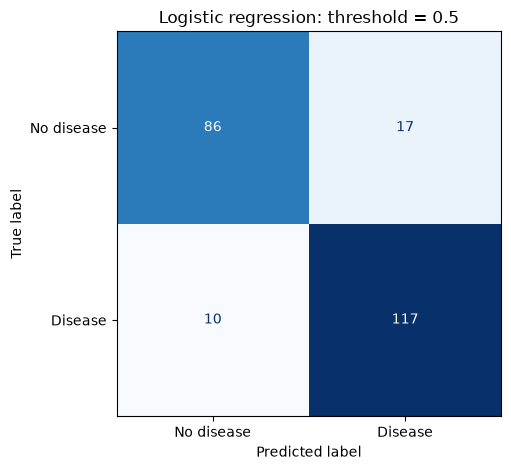

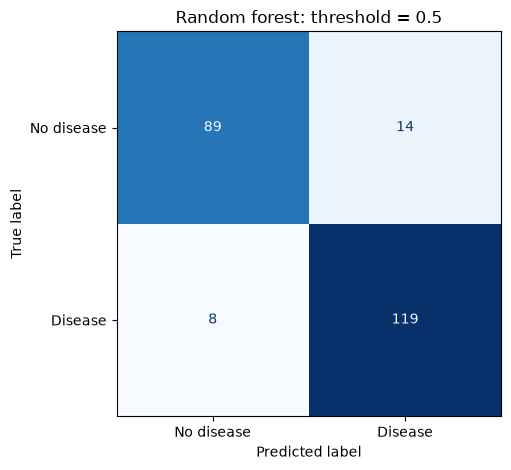

,Accuracy,ROC AUC,Precision,Recall
Model,,,,
Logistic regression,0.883,0.932,0.873,0.921
Random forest,0.904,0.944,0.895,0.937


In [22]:
heart_models = {}
heart_results = []

for name, estimator in [
    ("Logistic regression", LogisticRegression(max_iter=2000)),
    ("Random forest", RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
]:
    pipeline = Pipeline([
        ("preprocess", make_preprocess(heart_num, heart_cat)),
        ("model", estimator)
    ])

    pipeline.fit(Xheart_train, yheart_train)
    heart_models[name] = pipeline

    probability = pipeline.predict_proba(Xheart_valid)[:, 1]
    prediction = (probability >= 0.5).astype(int)

    heart_results.append({
        "Model": name,
        "Accuracy": accuracy_score(yheart_valid, prediction),
        "ROC AUC": roc_auc_score(yheart_valid, probability),
        "Precision": precision_score(yheart_valid, prediction),
        "Recall": recall_score(yheart_valid, prediction)
    })

    ConfusionMatrixDisplay.from_predictions(
        yheart_valid,
        prediction,
        labels=[0, 1],
        display_labels=["No disease", "Disease"],
        cmap="Blues",
        colorbar=False
    )
    plt.title(f"{name}: threshold = 0.5")
    plt.tight_layout()
    plt.show()

display(pd.DataFrame(heart_results).set_index("Model").round(3))

### Heart-disease classification: observations

At a decision threshold of 0.5, logistic regression achieved
accuracy 0.883 and ROC AUC 0.932, while random forest achieved
accuracy 0.904 and ROC AUC 0.944.

Random forest produced 119 true positives, 89 true negatives,
14 false positives and 8 false negatives. Logistic regression
produced 117 true positives, 86 true negatives, 17 false positives
and 10 false negatives.

Random forest performed better across all four reported metrics
on this validation split. However, this single split does not
establish that it will always outperform logistic regression.

### Decision memo: choosing a classification threshold

When missing a positive case costs more than raising a false
alarm, I would favour a lower decision threshold to increase
recall. For the breast-cancer classification exercise, I would
choose 0.30 rather than 0.50 based on the validation results.

Lowering the threshold reduced false negatives from 4 to 2 and
increased true positives from 49 to 51. Recall increased from
92.5% to 96.2%, while false positives remained at 1 on this split.
Precision remained approximately 98%.

A lower threshold can generally increase false positives,
although that did not happen in this comparison. The threshold
should reflect error costs and be selected using validation data.
Its performance should then be checked on an independent test set.

### Understanding questions

**1. Why is logistic regression a linear model even though it uses a nonlinear sigmoid function?**

Logistic regression applies the sigmoid function to a linear score,
z = wᵀx + b. The sigmoid converts this score into a probability,
but the log-odds remain linear in the input features. At a fixed
probability threshold, the decision boundary is therefore linear
in the feature space supplied to the model.

**2. Why should the probability model and decision threshold be treated separately?**

The model estimates a probability, while the threshold determines
which class is predicted. The same fitted model can use different
thresholds depending on the costs of false positives and false
negatives, without retraining. Lowering the threshold increases
or maintains recall, but may produce more false positives.
The threshold should be chosen using validation data and the
application's error costs, then evaluated on an independent test set.

**3. How does binary logistic regression extend to multiclass classification using softmax?**

For multiclass classification, the model calculates a linear score
for each class. Softmax converts these scores into class
probabilities that sum to one. Training minimises categorical
cross-entropy, and the default prediction is the class with the
highest probability. Evaluation can use a multiclass confusion
matrix and macro- or weighted-average precision, recall and F1.